In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Ellipse
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler


def visualize_embeddings(
    embeddings: np.ndarray,
    labels: np.ndarray,
    class_names: list,
    title: str,
    output_path: str = None,
    colors: list = None,
) -> None:
    """Create t-SNE visualization of embeddings

    Args:
        embeddings: Array of embeddings to visualize
        labels: Array of class labels (integers)
        class_names: List of class names corresponding to labels
        title: Title for the plot
        output_path: Optional path to save visualization. If None, plot will only be displayed.
        colors: Optional list of colors for classes. If None, will use default colors.
    """
    print(f"Creating t-SNE visualization for {title}...")

    if colors is None:
        colors = ["#E64B35", "#4DBBD5", "#00A087", "#3C5488"]

    n_samples = len(embeddings)
    perplexity = min(n_samples // 3, 50)

    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        early_exaggeration=12,
        learning_rate=200,
        init="pca",
        random_state=42,
        max_iter=2500,
        min_grad_norm=1e-7,
        metric="cosine",
        n_iter_without_progress=300,
    )

    scaler = StandardScaler()
    embeddings_scaled = scaler.fit_transform(embeddings)

    embeddings_2d = tsne.fit_transform(embeddings_scaled)

    print("Creating plot...")
    fig, ax = plt.subplots(figsize=(10, 8))
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")
    ax.grid(True, linestyle="-", alpha=0.2, color="gray", linewidth=0.5)

    for class_idx, class_name in enumerate(class_names):
        mask = labels == class_idx

        ax.scatter(
            embeddings_2d[mask, 0],
            embeddings_2d[mask, 1],
            c=[colors[class_idx]],
            label=class_name,
            alpha=0.6,
            s=40,
            edgecolor="none",
        )

        # Add centroid
        centroid = np.mean(embeddings_2d[mask], axis=0)
        ax.scatter(
            centroid[0],
            centroid[1],
            c="black",
            s=150,
            marker="*",
            edgecolor="white",
            linewidth=1,
            zorder=5,
        )

        # Add confidence ellipse
        if np.sum(mask) > 2:
            cov = np.cov(embeddings_2d[mask, 0], embeddings_2d[mask, 1])
            eigenvals, eigenvecs = np.linalg.eigh(cov)
            angle = np.degrees(np.arctan2(eigenvecs[1, 0], eigenvecs[0, 0]))

            ellip = Ellipse(
                xy=centroid,
                width=2 * 2 * np.sqrt(eigenvals[0]),
                height=2 * 2 * np.sqrt(eigenvals[1]),
                angle=angle,
                facecolor="none",
                edgecolor=colors[class_idx],
                alpha=0.3,
                linestyle="--",
                linewidth=0.75,
            )
            ax.add_patch(ellip)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for spine in ax.spines.values():
        spine.set_linewidth(0.75)

    ax.set_title(title, fontsize=11, pad=10, weight="bold")
    ax.set_xlabel("t-SNE Dimension 1", fontsize=10, labelpad=8)
    ax.set_ylabel("t-SNE Dimension 2", fontsize=10, labelpad=8)
    ax.tick_params(axis="both", which="major", labelsize=9, width=0.75, length=4)

    legend = ax.legend(
        title="Brain Tumor tumor_types",
        title_fontsize=10,
        fontsize=9,
        bbox_to_anchor=(1.05, 1),
        loc="upper left",
        borderaxespad=0,
        frameon=True,
        edgecolor="black",
        fancybox=False,
    )
    legend.get_frame().set_linewidth(0.75)

    ax.text(
        0.02,
        0.98,
        f"n = {len(embeddings)}",
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment="top",
    )

    plt.tight_layout()

    if output_path:
        plt.savefig(output_path, dpi=600, bbox_inches="tight")
        plt.close()
        print(f"Saved visualization to {output_path}")
    else:
        plt.show()

In [3]:
notes_df = pd.read_csv("/home/neob/ai/paper/data/eval/tumor_type_eval.csv")
labels = notes_df["class_label"].values
class_names = [
    "glioblastoma",  # 0
    "astrocytoma",  # 1
    "oligodendroglioma",  # 2
    "oligoastrocytoma",  # 3
]
notes_df.tumor_type.value_counts()

tumor_type
glioblastoma         1815
astrocytoma          1160
oligodendroglioma    1071
oligoastrocytoma      424
Name: count, dtype: int64

Creating t-SNE visualization for JINA Base...
Creating plot...


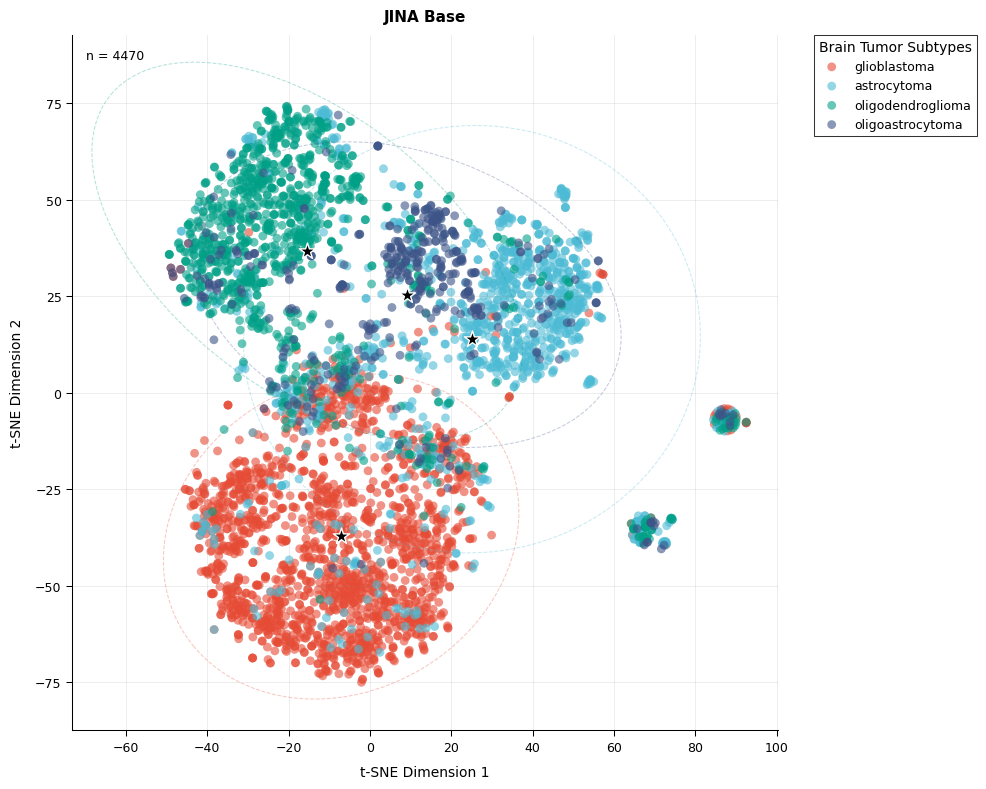

Creating t-SNE visualization for JINA Base (w text match)...
Creating plot...


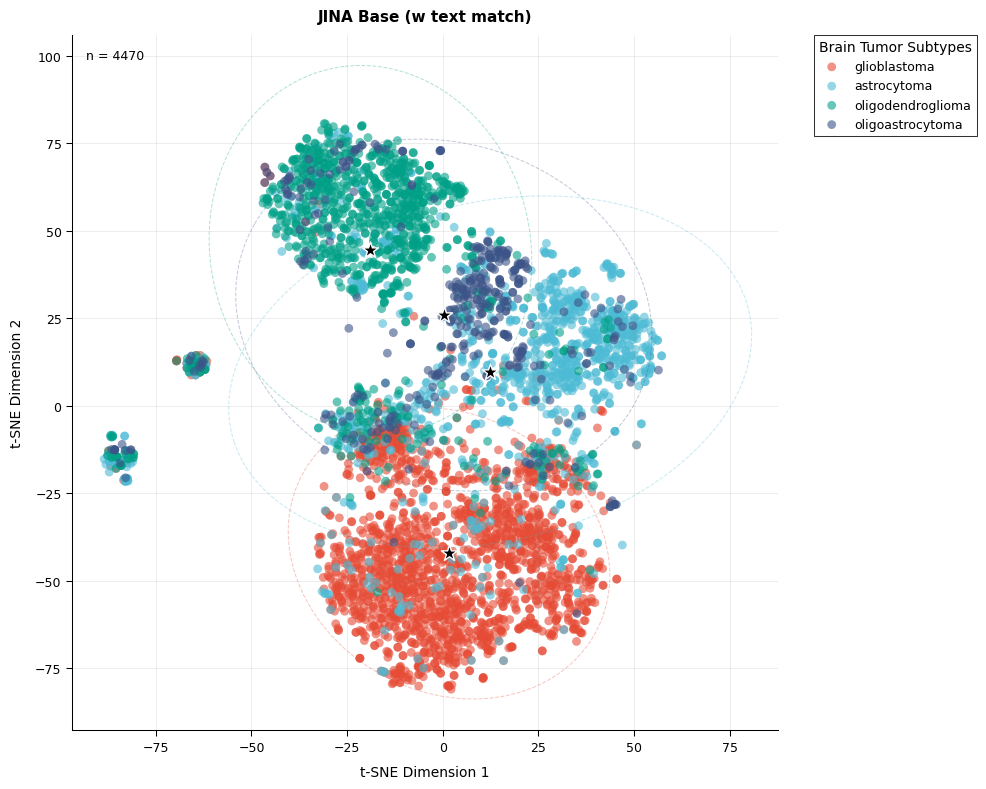

Creating t-SNE visualization for JINA finetuned...
Creating plot...


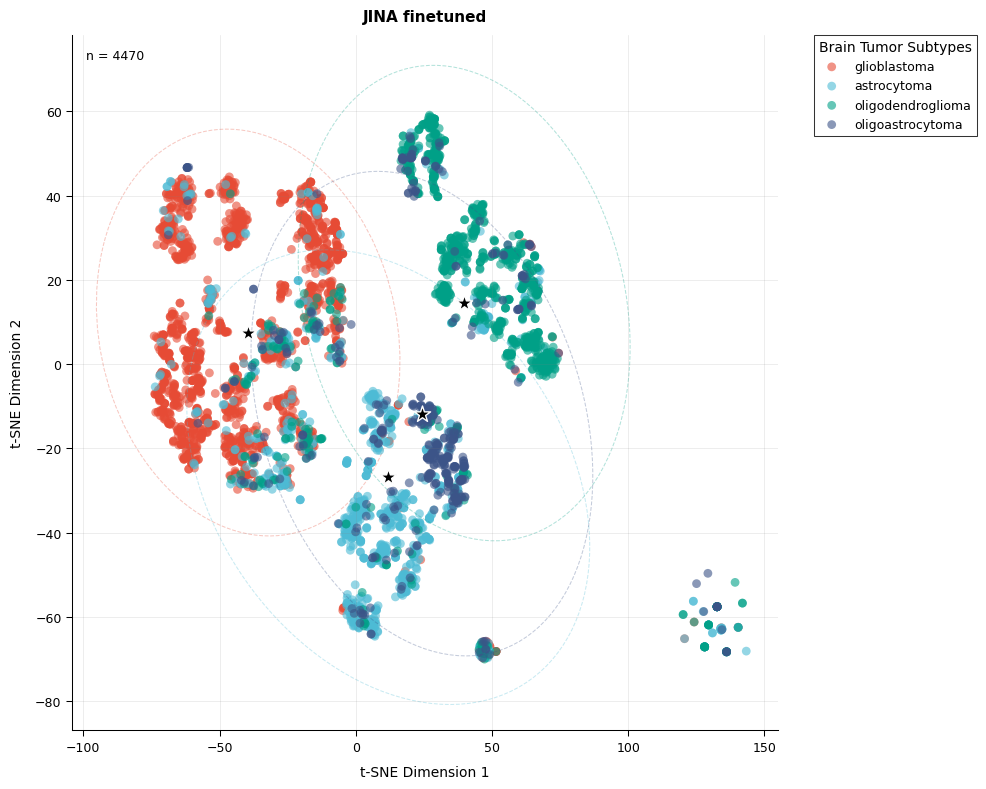

Creating t-SNE visualization for Gatatron Large...
Creating plot...


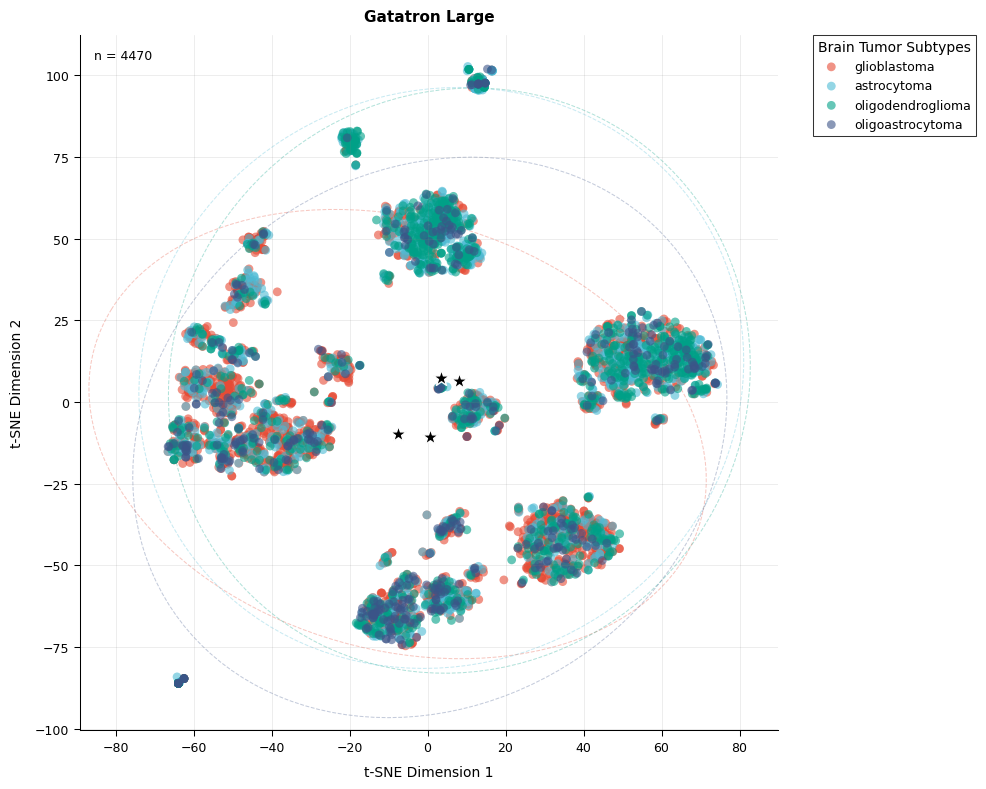

Creating t-SNE visualization for NV Embed v2...
Creating plot...


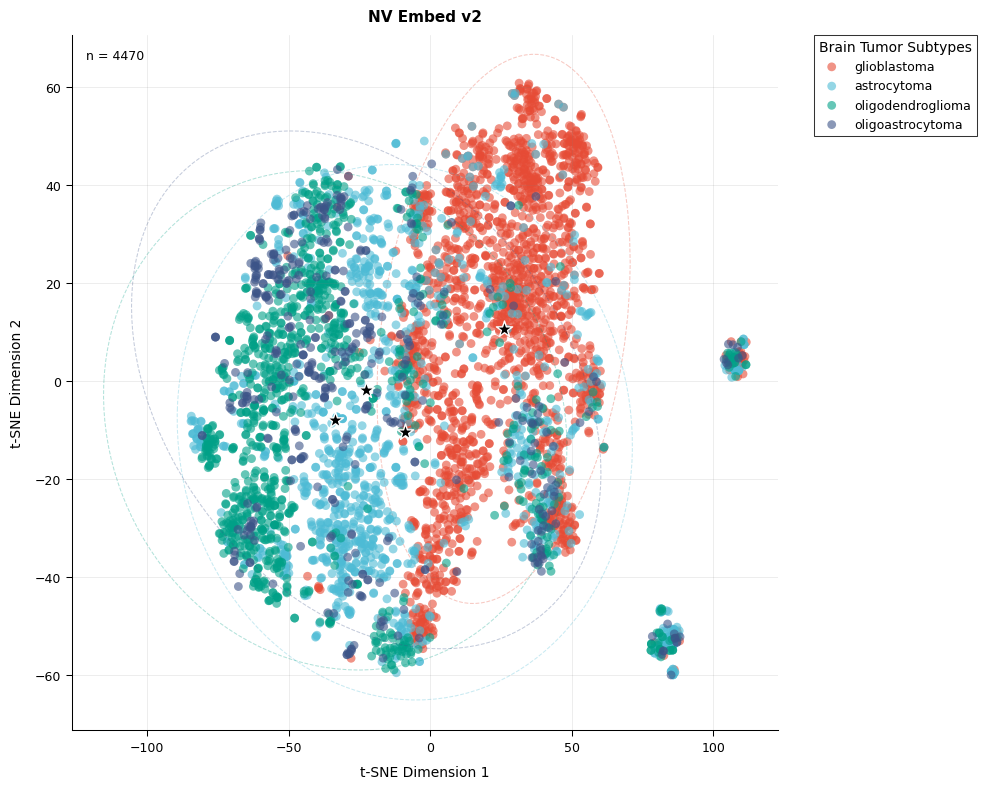

In [ ]:
visualize_embeddings(
    np.load("/home/neob/ai/paper/embeddings/tumor_type/jina_base.npy"),
    labels,
    class_names,
    "JINA Base",
)

visualize_embeddings(
    np.load("/home/neob/ai/paper/embeddings/tumor_type/jina_base_text_match.npy"),
    labels,
    class_names,
    "JINA Base (w text match)",
)


visualize_embeddings(
    np.load("/home/neob/ai/paper/embeddings/tumor_type/mnrl_higher_lr.npy"),
    labels,
    class_names,
    "JINA finetuned",
)


visualize_embeddings(
    np.load("/home/neob/ai/paper/embeddings/tumor_type/gatortron_large.npy"),
    labels,
    class_names,
    "Gatatron Large",
)


visualize_embeddings(
    np.load("/home/neob/ai/paper/embeddings/tumor_type/nv_embed_tumor_type.npy"),
    labels,
    class_names,
    "NV Embed v2",
)